# Week 2: Expected and observed outputs

Compare expected and actual outputs from each function's `all_observations.npz`. Predicted means and posterior standard deviations remain aligned to inputs and observations. The weekly JSON files are retained as tracking records.

The signed z-score is `(observed_output - expected_output) / std`: positive values indicate underprediction, and negative values indicate overprediction. Its magnitude measures error in units of predicted standard deviation. Scores are missing (`NaN`) when the standard deviation is missing or zero.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bayesian_bbo import FUNCTION_SPECS, load_observations

root = Path('../../data')
records = []

for function_id in FUNCTION_SPECS:
    function_directory = root / f'function_{function_id}'
    if not (function_directory / 'all_observations.npz').exists():
        continue
    observations = load_observations(root, function_id)
    matched = np.isfinite(observations.expected_outputs)
    for index in np.flatnonzero(matched):
        records.append({
            'function': function_id,
            'input': observations.inputs[index].tolist(),
            'expected_output': float(observations.expected_outputs[index]),
            'observed_output': float(observations.outputs[index]),
            'std': float(observations.stds[index]),
        })

if not records:
    raise ValueError('No observations have expected outputs yet.')

comparison = pd.DataFrame(records)
comparison['error'] = comparison['observed_output'] - comparison['expected_output']
comparison['absolute_error'] = comparison['error'].abs()
valid_std = comparison['std'].where(np.isfinite(comparison['std']) & (comparison['std'] > 0))
comparison['z_score'] = comparison['error'] / valid_std
comparison['absolute_z_score'] = comparison['z_score'].abs()
comparison

,function,input,expected_output,observed_output,std,error,absolute_error,z_score,absolute_z_score
0,1,"[0.835456, 0.75533]",0.001160,-3.459337e-42,0.000822,-0.001160,0.001160,-1.411377,1.411377
1,2,"[0.802058, 0.932779]",0.523564,1.263410e-01,0.170883,-0.397223,0.397223,-2.324530,2.324530
2,3,"[0.194638, 0.363906, 0.466721]",-0.072584,-5.894718e-03,0.076102,0.066689,0.066689,0.876316,0.876316
3,4,"[0.528998, 0.424017, 0.506366, 0.277697]",-8.973412,-3.336386e+00,5.530818,5.637026,5.637026,1.019203,1.019203
4,5,"[0.29667, 0.806944, 0.906495, 0.936907]",689.501455,1.397545e+03,200.322259,708.043654,708.043654,3.534523,3.534523
5,6,"[0.776415, 0.143718, 0.670225, 0.693095, 0.060...",-0.926655,-7.470712e-01,0.307780,0.179584,0.179584,0.583482,0.583482
6,7,"[0.167857, 0.467652, 0.068225, 0.169714, 0.420...",0.307150,1.085419e+00,0.301246,0.778269,0.778269,2.583504,2.583504
7,8,"[0.133138, 0.57364, 0.420506, 0.497998, 0.8321...",8.082127,9.428058e+00,0.932371,1.345931,1.345931,1.443558,1.443558


## Error summary

Summarize prediction error per function. Each function's outputs remain on its own scale.

In [2]:
summary = (
    comparison.groupby('function')
    .agg(
        observations=('error', 'size'),
        mean_expected=('expected_output', 'mean'),
        mean_observed=('observed_output', 'mean'),
        mean_error=('error', 'mean'),
        max_error=('error', 'max'),
        mean_std=('std', 'mean'),
        valid_z_scores=('z_score', 'count'),
        mean_z_score=('z_score', 'mean'),
        max_absolute_z_score=('absolute_z_score', 'max'),
    )
)
summary

,observations,mean_expected,mean_observed,mean_error,max_error,mean_std,valid_z_scores,mean_z_score,max_absolute_z_score
function,,,,,,,,,
1,1,0.001160,-3.459337e-42,-0.001160,-0.001160,0.000822,1,-1.411377,1.411377
2,1,0.523564,1.263410e-01,-0.397223,-0.397223,0.170883,1,-2.324530,2.324530
3,1,-0.072584,-5.894718e-03,0.066689,0.066689,0.076102,1,0.876316,0.876316
4,1,-8.973412,-3.336386e+00,5.637026,5.637026,5.530818,1,1.019203,1.019203
5,1,689.501455,1.397545e+03,708.043654,708.043654,200.322259,1,3.534523,3.534523
6,1,-0.926655,-7.470712e-01,0.179584,0.179584,0.307780,1,0.583482,0.583482
7,1,0.307150,1.085419e+00,0.778269,0.778269,0.301246,1,2.583504,2.583504
8,1,8.082127,9.428058e+00,1.345931,1.345931,0.932371,1,1.443558,1.443558


## Expected versus observed

Each panel uses an independent y-axis so functions with different output scales can be compared without one dominating the chart.

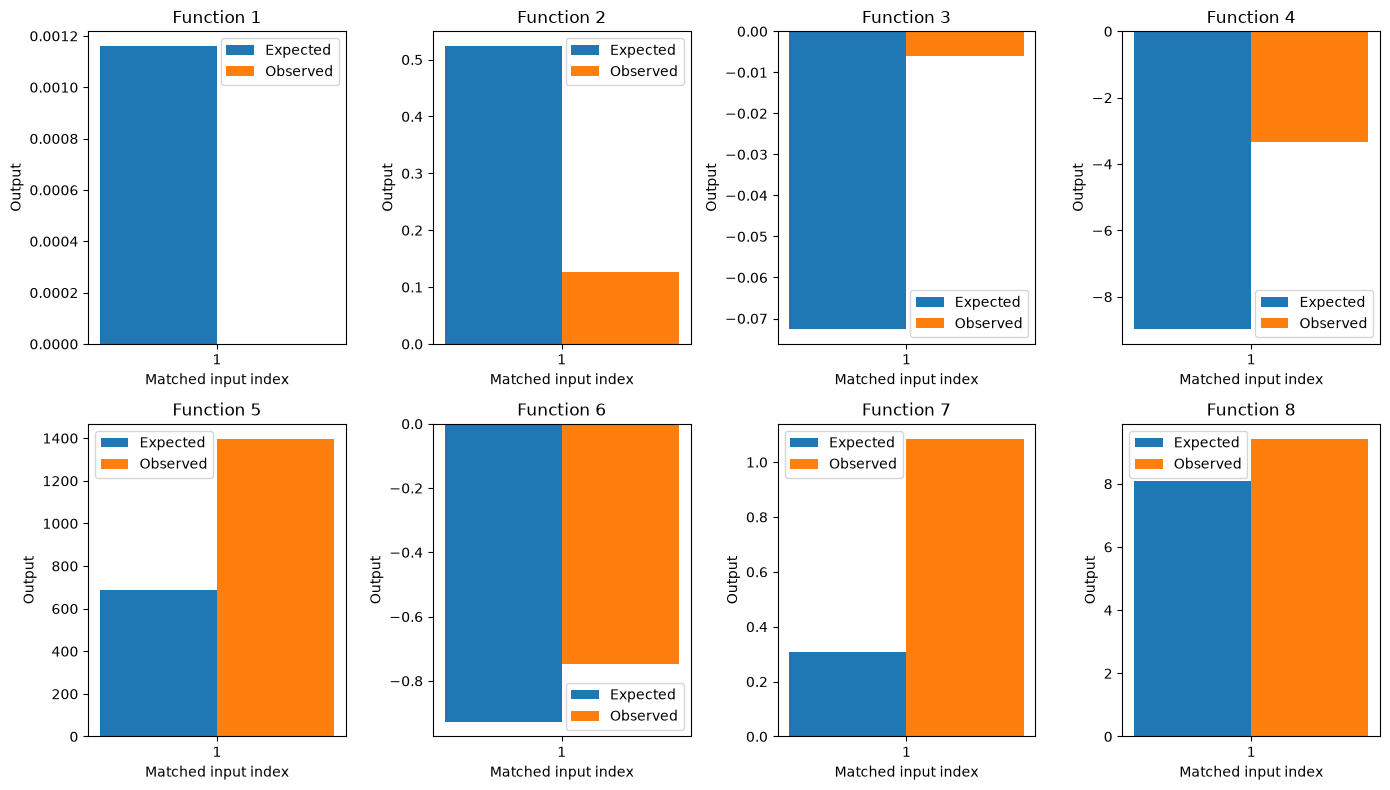

In [3]:
function_ids = sorted(comparison['function'].unique())
fig, axes = plt.subplots(2, 4, figsize=(14, 8), squeeze=False)
axes = axes.ravel()

for ax, function_id in zip(axes, function_ids):
    rows = comparison[comparison['function'] == function_id]
    positions = np.arange(len(rows))
    width = 0.38
    ax.bar(positions - width / 2, rows['expected_output'], width, label='Expected')
    ax.bar(positions + width / 2, rows['observed_output'], width, label='Observed')
    ax.set_title(f'Function {function_id}')
    ax.set_xlabel('Matched input index')
    ax.set_ylabel('Output')
    ax.set_xticks(positions, [str(index + 1) for index in positions])
    ax.axhline(0, color='black', linewidth=0.7)
    ax.legend()

for ax in axes[len(function_ids):]:
    ax.set_visible(False)

fig.tight_layout()
plt.show()